# Lottery Ticket Comparison Report

This report compares every saved model from the EfficientNetB0 lottery-ticket experiment against the **baseline EfficientNetB0 trained on the same resized data** (`resized/models/EfficientNetB0.keras`).

It reads the saved CSV/JSON/test-prediction artifacts only — it does **not** retrain anything.

Size definitions:
- **effective MB** = nonzero parameters × 4 bytes (the LTH-relevant size)
- **sparse MB** = `.npz` index+value file size (tickets only)
- **keras MB** = dense `.keras` file size (zeros are still stored)
- **TFLite dynamic MB** = deployable compressed size where available

Production TFLite and latency are unavailable and are shown as **N/A**.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import roc_curve, auc

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)

In [2]:
def find_project_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "resized" / "lottery_ticket" / "lth_vs_resized_efficientnet.csv").exists():
            return p
    raise FileNotFoundError("Could not locate resized/lottery_ticket/lth_vs_resized_efficientnet.csv")

ROOT = find_project_root()
OUT_ROOT = ROOT / "resized" / "lottery_ticket"
df = pd.read_csv(OUT_ROOT / "lth_vs_resized_efficientnet.csv")
prod_eval = json.loads((OUT_ROOT / "production_eval.json").read_text())

MAX_F1_DROP = 0.01
base_val = df[df["stage"] == "baseline"].set_index("init")["val_f1"].to_dict()

def status_of(row):
    if row["stage"] != "ticket":
        return "reference"
    b = base_val.get(row["init"], np.nan)
    if pd.isna(b) or pd.isna(row["val_f1"]):
        return "unknown"
    return "accepted" if row["val_f1"] >= b - MAX_F1_DROP else "stopped"

df["status"] = df.apply(status_of, axis=1)

def label_of(row):
    if row["stage"] == "production":
        s = "Baseline (resized EfficientNetB0)"
    elif row["stage"] == "baseline":
        s = f"LTH {row['init']} baseline"
    else:
        s = f"{row['init']} {int(round(row['actual_sparsity'] * 100))}%"
    if row["status"] == "stopped":
        s += " (stopped)"
    return s

df["label"] = df.apply(label_of, axis=1)
prod = df[df["stage"] == "production"].iloc[0]

init_colors = {"pretrained": "#4C72B0", "random": "#DD8452"}
df["color"] = df.apply(
    lambda r: "#C44E52" if r["stage"] == "production" else init_colors.get(r["init"], "#777777"),
    axis=1,
)

print(f"Loaded {len(df)} models from {OUT_ROOT / 'lth_vs_resized_efficientnet.csv'}")
print("Status counts:", df["status"].value_counts().to_dict())

Loaded 12 models from /home/jackm/liceDetection/ParasiteID/resized/lottery_ticket/lth_vs_resized_efficientnet.csv
Status counts: {'accepted': 7, 'reference': 3, 'stopped': 2}


In [3]:
table_cols = [
    "label", "stage", "actual_sparsity", "val_f1", "val_auc",
    "test_acc", "test_precision", "test_recall", "test_f1", "test_auc",
    "comb_detect_pct", "comb_false_pct", "effective_mb", "sparse_mb",
    "tflite_dyn_mb", "keras_mb", "status",
]
stage_order = {"production": 0, "baseline": 1, "ticket": 2}
show = (
    df.assign(_stage_order=df["stage"].map(stage_order))
      .sort_values(["_stage_order", "init", "actual_sparsity"])
      [table_cols]
      .copy()
)

def fmt(v, digits=3):
    if pd.isna(v):
        return "N/A"
    if isinstance(v, (int, np.integer)):
        return str(v)
    if abs(v) >= 100:
        return f"{v:.1f}"
    return f"{v:.{digits}f}"

for c in table_cols:
    if c not in ("label", "stage", "status"):
        show[c] = show[c].map(fmt)

display(show)

,label,stage,actual_sparsity,val_f1,val_auc,test_acc,test_precision,test_recall,test_f1,test_auc,comb_detect_pct,comb_false_pct,effective_mb,sparse_mb,tflite_dyn_mb,keras_mb,status
0,Baseline (resized EfficientNetB0),production,0.000,N/A,N/A,0.960,0.979,0.913,0.945,0.992,100.0,1.042,16.203,N/A,N/A,17.044,reference
1,LTH pretrained baseline,baseline,0.000,0.990,1.000,0.983,0.980,0.973,0.977,0.999,90.625,0.000,16.203,N/A,4.582,17.052,reference
10,LTH random baseline,baseline,0.000,0.868,0.963,0.918,0.898,0.880,0.889,0.952,20.833,6.250,16.203,N/A,4.577,17.049,reference
2,pretrained 10%,ticket,0.100,0.993,1.000,0.988,0.993,0.973,0.983,0.999,96.875,0.000,14.620,19.546,4.582,17.052,accepted
3,pretrained 20%,ticket,0.200,0.993,1.000,0.988,0.993,0.973,0.983,1.000,100.0,0.000,13.037,17.347,N/A,17.052,accepted
4,pretrained 30%,ticket,0.300,0.990,1.000,0.985,0.986,0.973,0.980,0.999,100.0,0.000,11.454,15.115,N/A,17.052,accepted
5,pretrained 40%,ticket,0.400,0.993,1.000,0.985,0.986,0.973,0.980,0.999,100.0,0.000,9.871,12.900,N/A,17.052,accepted
6,pretrained 50%,ticket,0.500,0.990,1.000,0.988,0.993,0.973,0.983,1.000,73.958,1.042,8.288,10.788,N/A,17.052,accepted
7,pretrained 60%,ticket,0.600,0.993,1.000,0.990,1.000,0.973,0.986,0.999,100.0,0.000,6.705,8.664,4.582,17.052,accepted
8,pretrained 70%,ticket,0.700,0.983,0.999,0.973,0.960,0.967,0.963,0.997,100.0,3.125,5.122,6.544,N/A,17.052,accepted


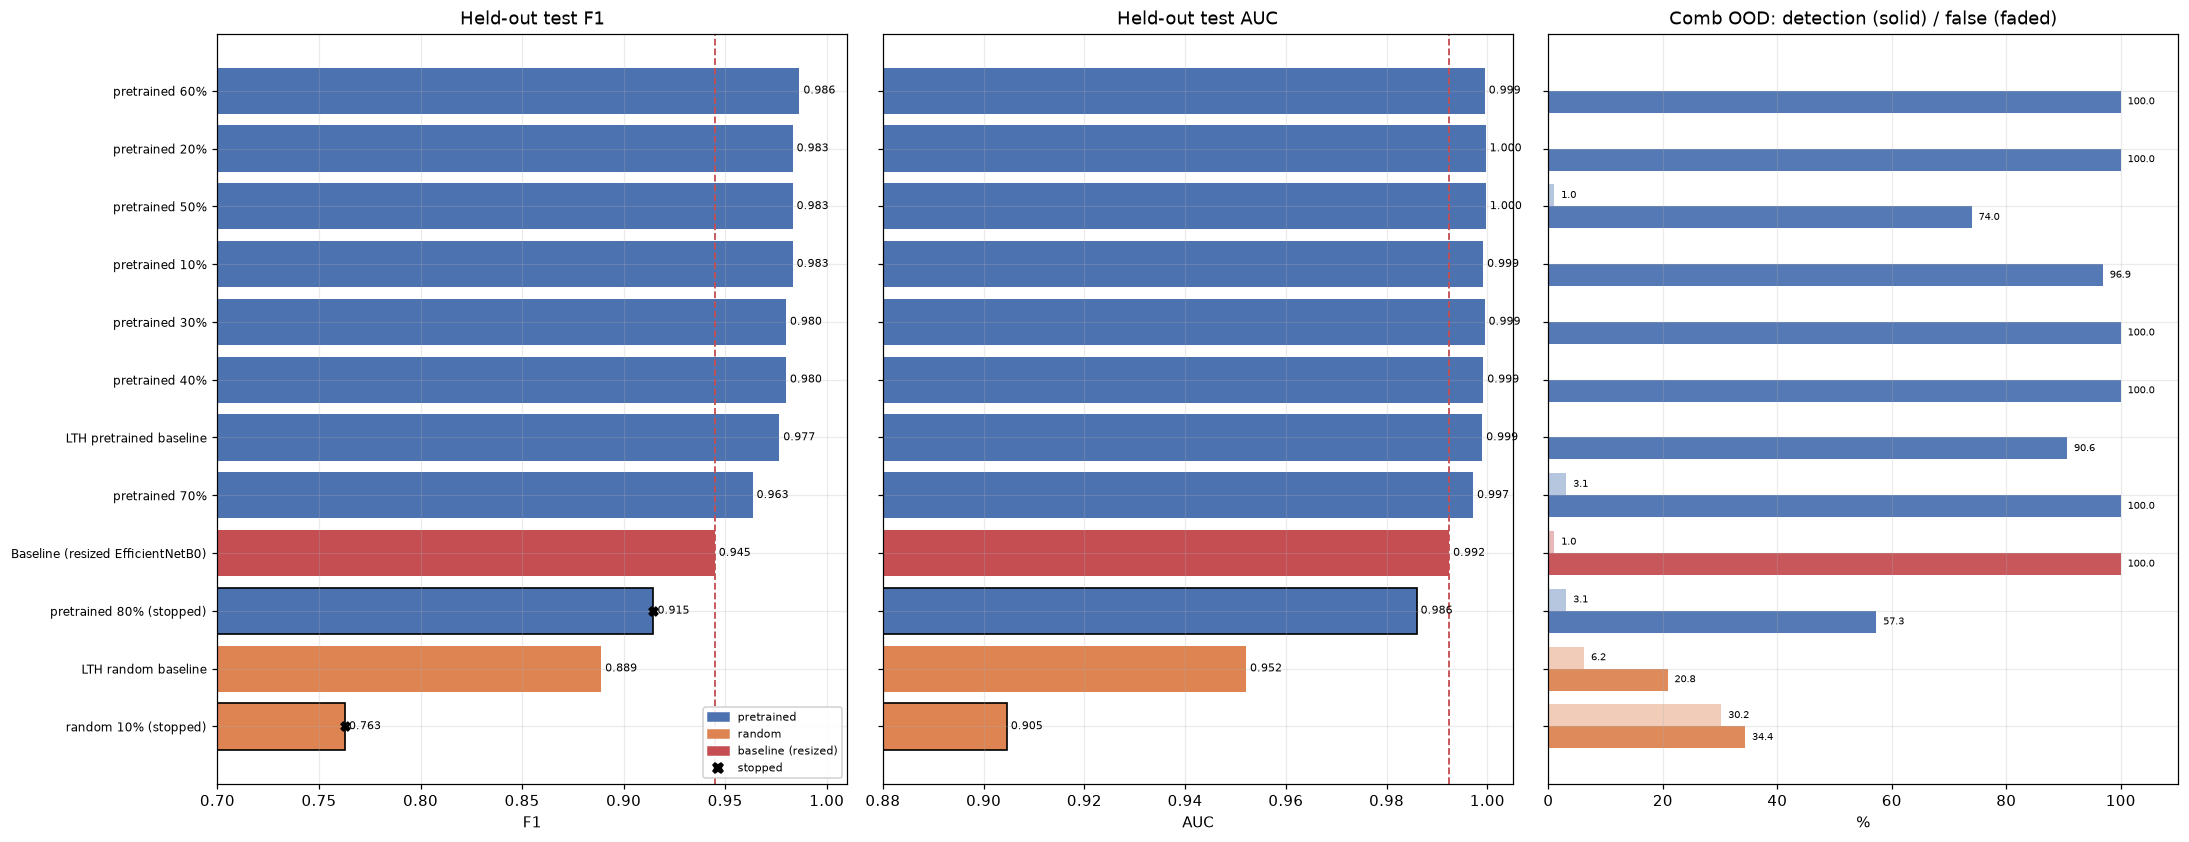

In [4]:
plot_df = df.sort_values("test_f1", ascending=True).reset_index(drop=True)
y = np.arange(len(plot_df))
fig, axes = plt.subplots(1, 3, figsize=(20, max(5.5, 0.48 * len(plot_df) + 2)), sharey=True)

ax = axes[0]
ax.barh(y, plot_df["test_f1"], color=plot_df["color"],
        edgecolor=["black" if s == "stopped" else "none" for s in plot_df["status"]],
        linewidth=1.1)
ax.axvline(prod["test_f1"], color="#C44E52", ls="--", lw=1.2)
for yi, (v, s) in enumerate(zip(plot_df["test_f1"], plot_df["status"])):
    if pd.notna(v):
        ax.text(v + 0.002, yi, f"{v:.3f}", va="center", fontsize=7)
    if s == "stopped":
        ax.scatter(v, yi, marker="X", color="black", s=34, zorder=5)
ax.set_yticks(y)
ax.set_yticklabels(plot_df["label"], fontsize=8)
ax.set_xlim(0.70, 1.01)
ax.set_xlabel("F1")
ax.set_title("Held-out test F1")

ax = axes[1]
ax.barh(y, plot_df["test_auc"], color=plot_df["color"],
        edgecolor=["black" if s == "stopped" else "none" for s in plot_df["status"]],
        linewidth=1.1)
ax.axvline(prod["test_auc"], color="#C44E52", ls="--", lw=1.2)
for yi, v in enumerate(plot_df["test_auc"]):
    if pd.notna(v):
        ax.text(v + 0.0008, yi, f"{v:.3f}", va="center", fontsize=7)
ax.set_xlim(0.88, 1.005)
ax.set_xlabel("AUC")
ax.set_title("Held-out test AUC")

ax = axes[2]
h = 0.38
ax.barh(y - h / 2, plot_df["comb_detect_pct"], height=h, color=plot_df["color"], alpha=0.95)
ax.barh(y + h / 2, plot_df["comb_false_pct"], height=h, color=plot_df["color"], alpha=0.40)
for yi, (d, f) in enumerate(zip(plot_df["comb_detect_pct"], plot_df["comb_false_pct"])):
    if pd.notna(d):
        ax.text(min(d + 1.2, 103), yi - h / 2, f"{d:.1f}", va="center", fontsize=6.5)
    if pd.notna(f) and f > 0.5:
        ax.text(f + 1.2, yi + h / 2, f"{f:.1f}", va="center", fontsize=6.5)
ax.set_xlim(0, 110)
ax.set_xlabel("%")
ax.set_title("Comb OOD: detection (solid) / false (faded)")

handles = [
    Patch(color=init_colors["pretrained"], label="pretrained"),
    Patch(color=init_colors["random"], label="random"),
    Patch(color="#C44E52", label="baseline (resized)"),
    Line2D([0], [0], marker="X", color="none", markerfacecolor="black",
           markeredgecolor="black", markersize=7, label="stopped"),
]
axes[0].legend(handles=handles, loc="lower right", fontsize=7, framealpha=0.9)
plt.tight_layout()
fig.savefig(OUT_ROOT / "lth_report_all_models_performance.png", dpi=130, bbox_inches="tight")
plt.show()

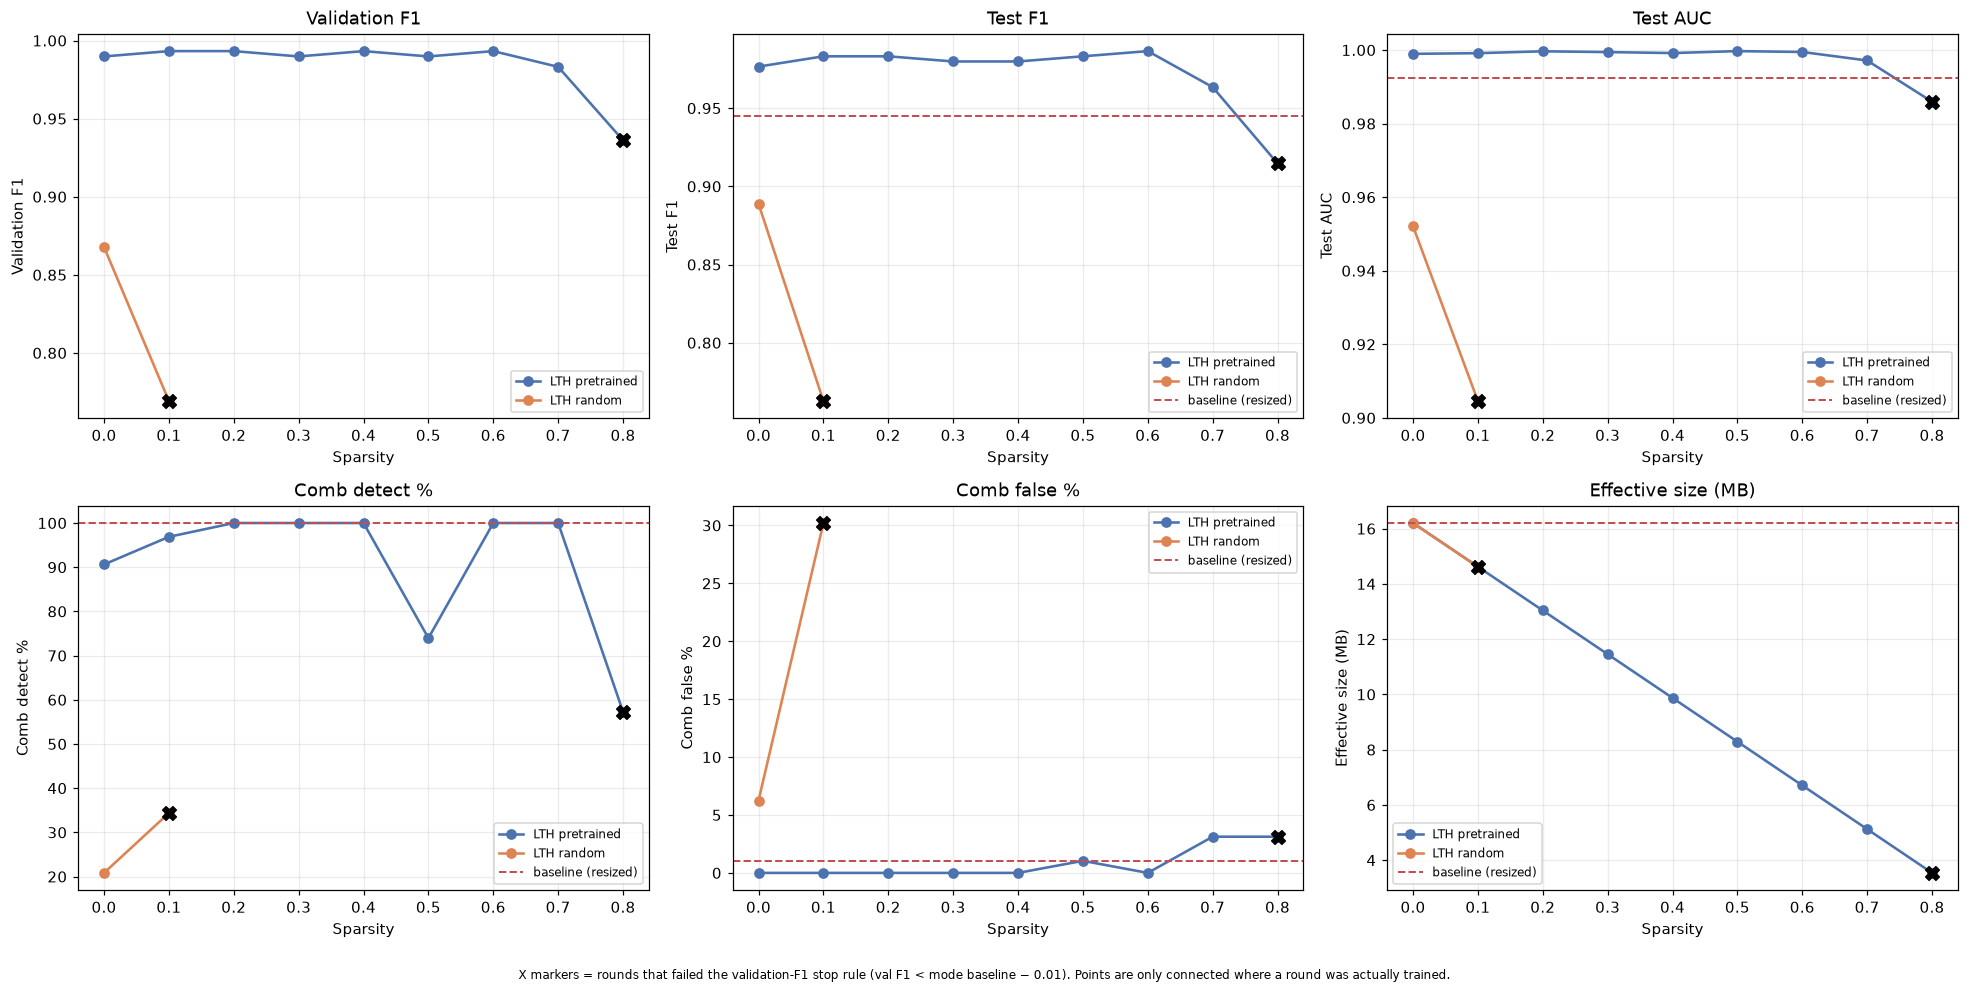

In [5]:
metrics = [
    ("val_f1", "Validation F1", None),
    ("test_f1", "Test F1", prod["test_f1"]),
    ("test_auc", "Test AUC", prod["test_auc"]),
    ("comb_detect_pct", "Comb detect %", prod["comb_detect_pct"]),
    ("comb_false_pct", "Comb false %", prod["comb_false_pct"]),
    ("effective_mb", "Effective size (MB)", prod["effective_mb"]),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, title, ref) in zip(axes.ravel(), metrics):
    for init in ("pretrained", "random"):
        sub = df[(df["init"] == init) & (df["stage"].isin(["baseline", "ticket"]))].sort_values("actual_sparsity")
        if sub.empty:
            continue
        color = init_colors[init]
        ax.plot(sub["actual_sparsity"], sub[col], marker="o", color=color,
                lw=1.7, label=f"LTH {init}")
        for _, r in sub.iterrows():
            if r["status"] == "stopped":
                ax.scatter(r["actual_sparsity"], r[col], marker="X", s=80,
                           color="black", zorder=6)
    if ref is not None and pd.notna(ref):
        ax.axhline(ref, color="#C44E52", ls="--", lw=1.3, label="baseline (resized)")
    ax.set_title(title)
    ax.set_xlabel("Sparsity")
    ax.set_ylabel(title)
    ax.set_xticks(np.arange(0, 0.9, 0.1))
    ax.legend(fontsize=8)
fig.text(0.5, 0.005,
         "X markers = rounds that failed the validation-F1 stop rule (val F1 < mode baseline − 0.01). "
         "Points are only connected where a round was actually trained.",
         ha="center", fontsize=8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUT_ROOT / "lth_report_performance_vs_sparsity.png", dpi=130, bbox_inches="tight")
plt.show()

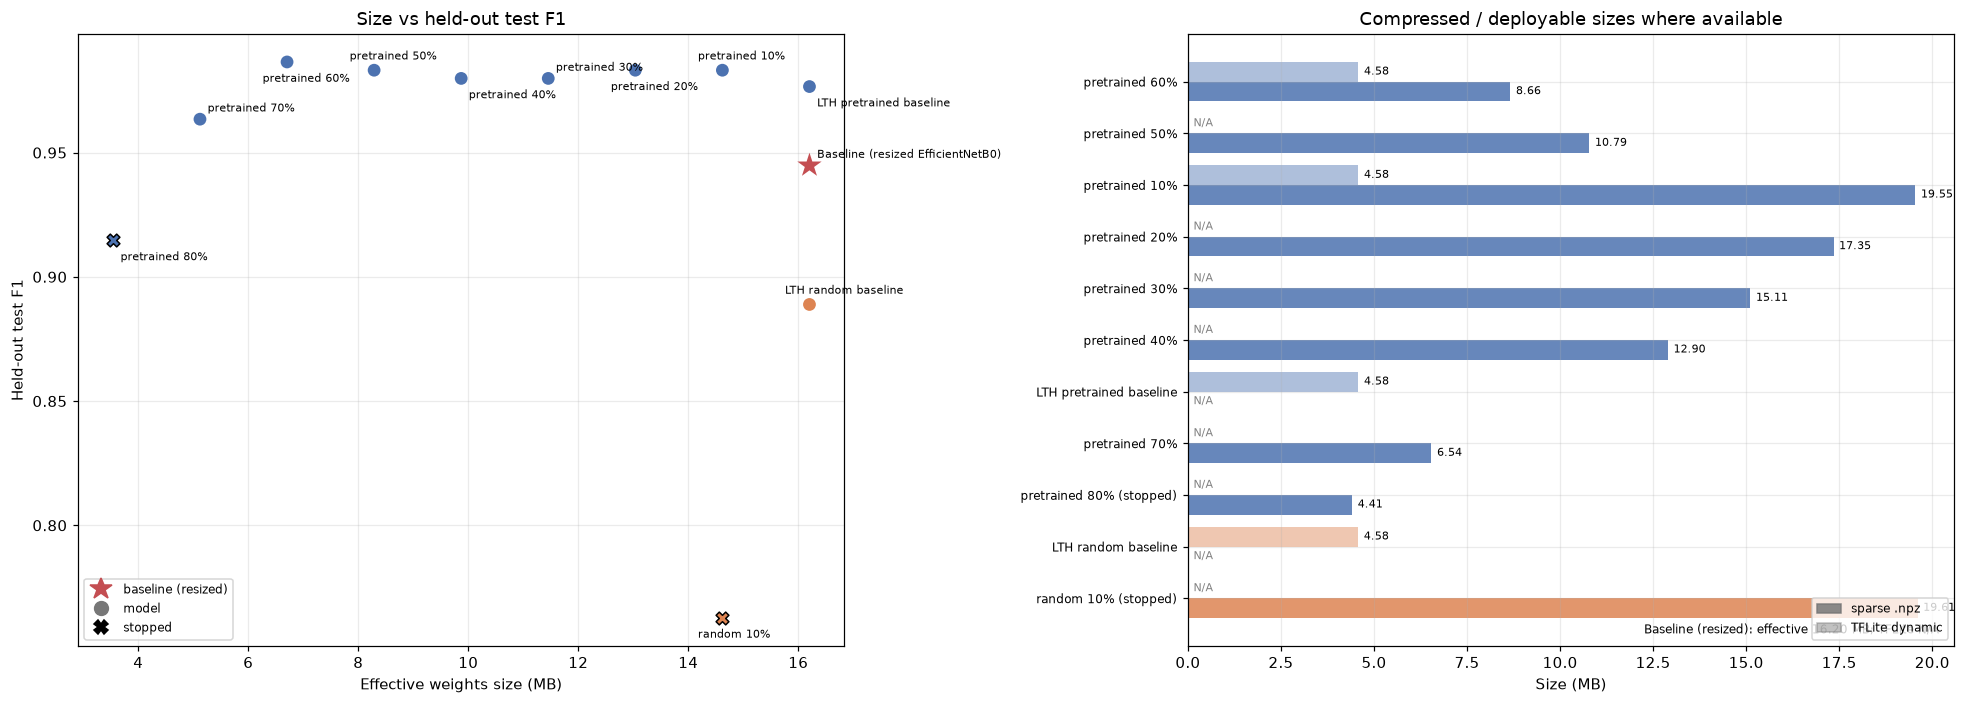

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

ax = axes[0]
offsets = [(5, 5), (5, -13), (-16, 7), (-16, -13)]
for i, (_, r) in enumerate(df.iterrows()):
    marker = "*" if r["stage"] == "production" else ("o" if r["status"] != "stopped" else "X")
    size = 280 if r["stage"] == "production" else 70
    ax.scatter(r["effective_mb"], r["test_f1"], marker=marker, s=size,
               color=r["color"], edgecolor="black" if r["status"] == "stopped" else "none",
               linewidth=1.0, zorder=5 if r["stage"] == "production" else 3)
    short = r["label"].replace(" (stopped)", "")
    dx, dy = offsets[i % len(offsets)]
    ax.annotate(short, (r["effective_mb"], r["test_f1"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=7)
ax.set_xlabel("Effective weights size (MB)")
ax.set_ylabel("Held-out test F1")
ax.set_title("Size vs held-out test F1")
ax.legend(handles=[
    Line2D([0], [0], marker="*", color="none", markerfacecolor="#C44E52",
           markeredgecolor="#C44E52", markersize=15, label="baseline (resized)"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#777777",
           markeredgecolor="#777777", markersize=9, label="model"),
    Line2D([0], [0], marker="X", color="none", markerfacecolor="black",
           markeredgecolor="black", markersize=9, label="stopped"),
], loc="lower left", fontsize=8)

ax = axes[1]
bar_df = df[df["sparse_mb"].notna() | df["tflite_dyn_mb"].notna()].sort_values("test_f1")
yb = np.arange(len(bar_df))
hb = 0.38
ax.barh(yb - hb / 2, bar_df["sparse_mb"], height=hb, color=bar_df["color"], alpha=0.85)
ax.barh(yb + hb / 2, bar_df["tflite_dyn_mb"], height=hb, color=bar_df["color"], alpha=0.45)
for yi, (sparse, tflite) in enumerate(zip(bar_df["sparse_mb"], bar_df["tflite_dyn_mb"])):
    if pd.notna(sparse):
        ax.text(sparse + 0.15, yi - hb / 2, f"{sparse:.2f}", va="center", fontsize=7)
    else:
        ax.text(0.15, yi - hb / 2, "N/A", va="center", fontsize=7, color="gray")
    if pd.notna(tflite):
        ax.text(tflite + 0.15, yi + hb / 2, f"{tflite:.2f}", va="center", fontsize=7)
    else:
        ax.text(0.15, yi + hb / 2, "N/A", va="center", fontsize=7, color="gray")
ax.set_yticks(yb)
ax.set_yticklabels(bar_df["label"], fontsize=8)
ax.set_xlabel("Size (MB)")
ax.set_title("Compressed / deployable sizes where available")
ax.legend(handles=[
    Patch(color="#777777", alpha=0.85, label="sparse .npz"),
    Patch(color="#777777", alpha=0.45, label="TFLite dynamic"),
], loc="lower right", fontsize=8)
ax.text(0.98, 0.02,
        f"Baseline (resized): effective {prod['effective_mb']:.2f} MB; TFLite N/A",
        transform=ax.transAxes, ha="right", fontsize=8)

plt.tight_layout()
fig.savefig(OUT_ROOT / "lth_report_size_vs_performance.png", dpi=130, bbox_inches="tight")
plt.show()

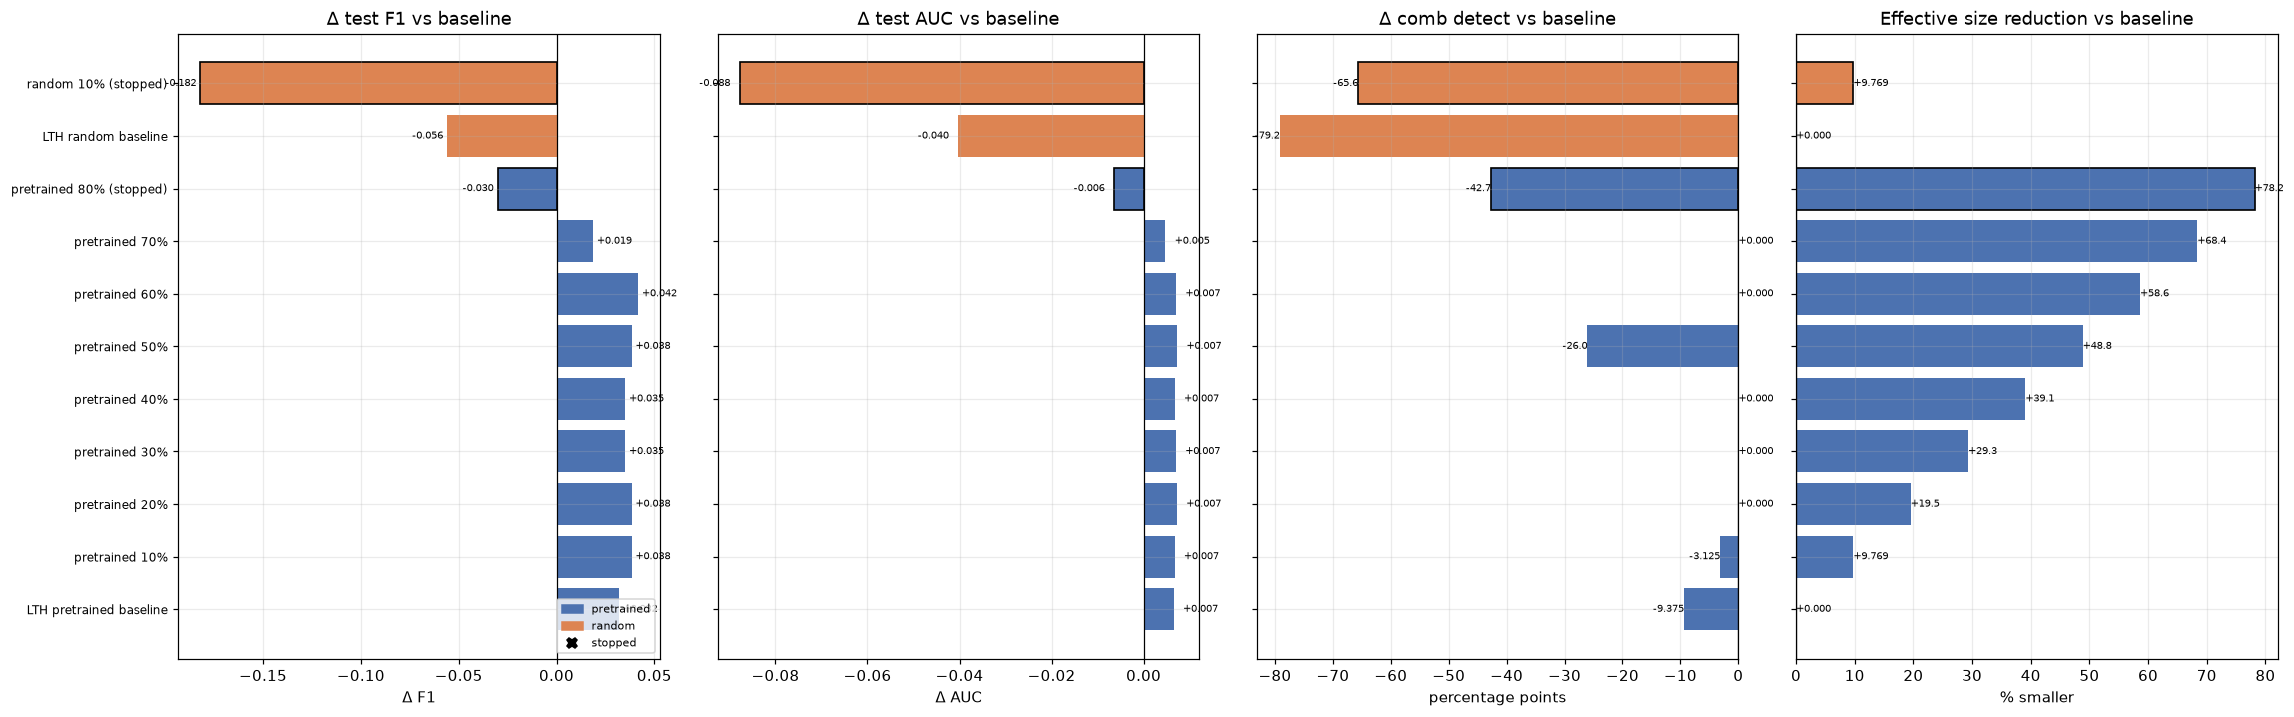

In [7]:
base = prod
delta = df[df["stage"] != "production"].copy()
delta["d_test_f1"] = delta["test_f1"] - base["test_f1"]
delta["d_test_auc"] = delta["test_auc"] - base["test_auc"]
delta["d_comb_detect"] = delta["comb_detect_pct"] - base["comb_detect_pct"]
delta["size_reduction_pct"] = (1.0 - delta["effective_mb"] / base["effective_mb"]) * 100.0
delta = delta.sort_values(["init", "actual_sparsity"]).reset_index(drop=True)

metrics = [
    ("d_test_f1", "Δ test F1 vs baseline", "Δ F1"),
    ("d_test_auc", "Δ test AUC vs baseline", "Δ AUC"),
    ("d_comb_detect", "Δ comb detect vs baseline", "percentage points"),
    ("size_reduction_pct", "Effective size reduction vs baseline", "% smaller"),
]
fig, axes = plt.subplots(1, 4, figsize=(21, max(5, 0.42 * len(delta) + 2)), sharey=True)
yy = np.arange(len(delta))
for ax, (col, title, xlabel) in zip(axes, metrics):
    ax.barh(yy, delta[col], color=delta["color"],
            edgecolor=["black" if s == "stopped" else "none" for s in delta["status"]],
            linewidth=1.1)
    ax.axvline(0, color="black", lw=0.8)
    for yi, v in enumerate(delta[col]):
        if pd.notna(v):
            ax.text(v + (0.002 if v >= 0 else -0.002), yi, f"{v:+.3f}" if abs(v) < 10 else f"{v:+.1f}",
                    va="center", ha="left" if v >= 0 else "right", fontsize=6.5)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
axes[0].set_yticks(yy)
axes[0].set_yticklabels(delta["label"], fontsize=8)
handles = [
    Patch(color=init_colors["pretrained"], label="pretrained"),
    Patch(color=init_colors["random"], label="random"),
    Line2D([0], [0], marker="X", color="none", markerfacecolor="black",
           markeredgecolor="black", markersize=7, label="stopped"),
]
axes[0].legend(handles=handles, loc="lower right", fontsize=7)
plt.tight_layout()
fig.savefig(OUT_ROOT / "lth_report_deltas_vs_baseline.png", dpi=130, bbox_inches="tight")
plt.show()

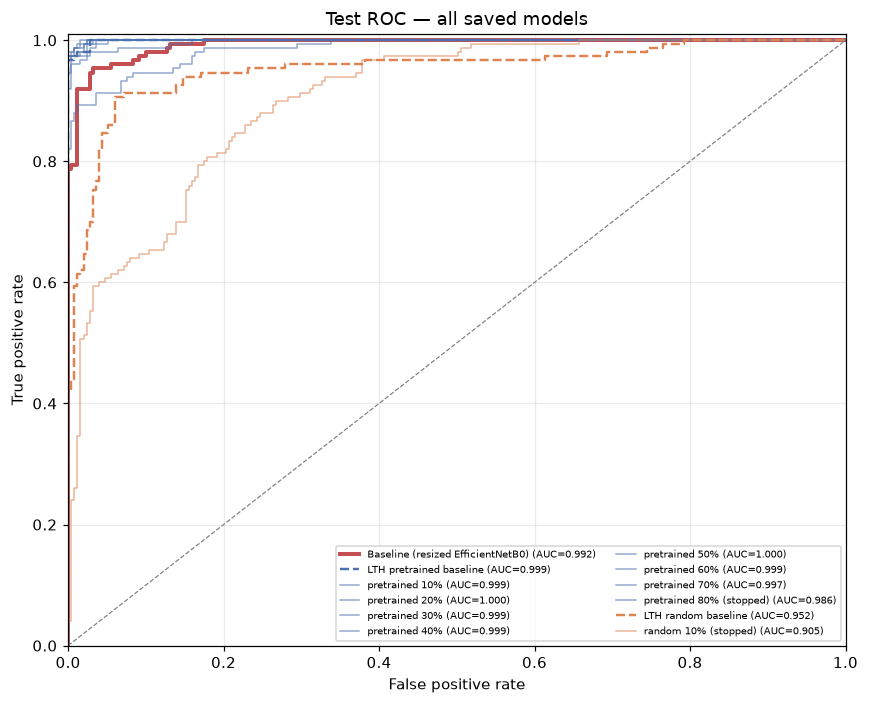

In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
for _, r in df.iterrows():
    if r["stage"] == "production":
        p = OUT_ROOT / "production_test_predictions.csv"
    else:
        p = OUT_ROOT / r["init"] / f"{r['tag']}_test_predictions.csv"
    if not p.exists():
        print("missing predictions:", p)
        continue
    pred = pd.read_csv(p)
    fpr, tpr, _ = roc_curve(pred["y_true"], pred["prob_nits"])
    roc_auc = auc(fpr, tpr)
    color = "#C44E52" if r["stage"] == "production" else init_colors.get(r["init"], "#777777")
    ls = "--" if r["stage"] == "baseline" else "-"
    lw = 2.6 if r["stage"] == "production" else (1.6 if r["stage"] == "baseline" else 1.0)
    alpha = 1.0 if r["stage"] in ("production", "baseline") else 0.6
    ax.plot(fpr, tpr, color=color, ls=ls, lw=lw, alpha=alpha,
            label=f"{r['label']} (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC — all saved models")
ax.legend(fontsize=6.5, ncol=2, loc="lower right")
plt.tight_layout()
fig.savefig(OUT_ROOT / "lth_report_roc_all_models.png", dpi=130, bbox_inches="tight")
plt.show()

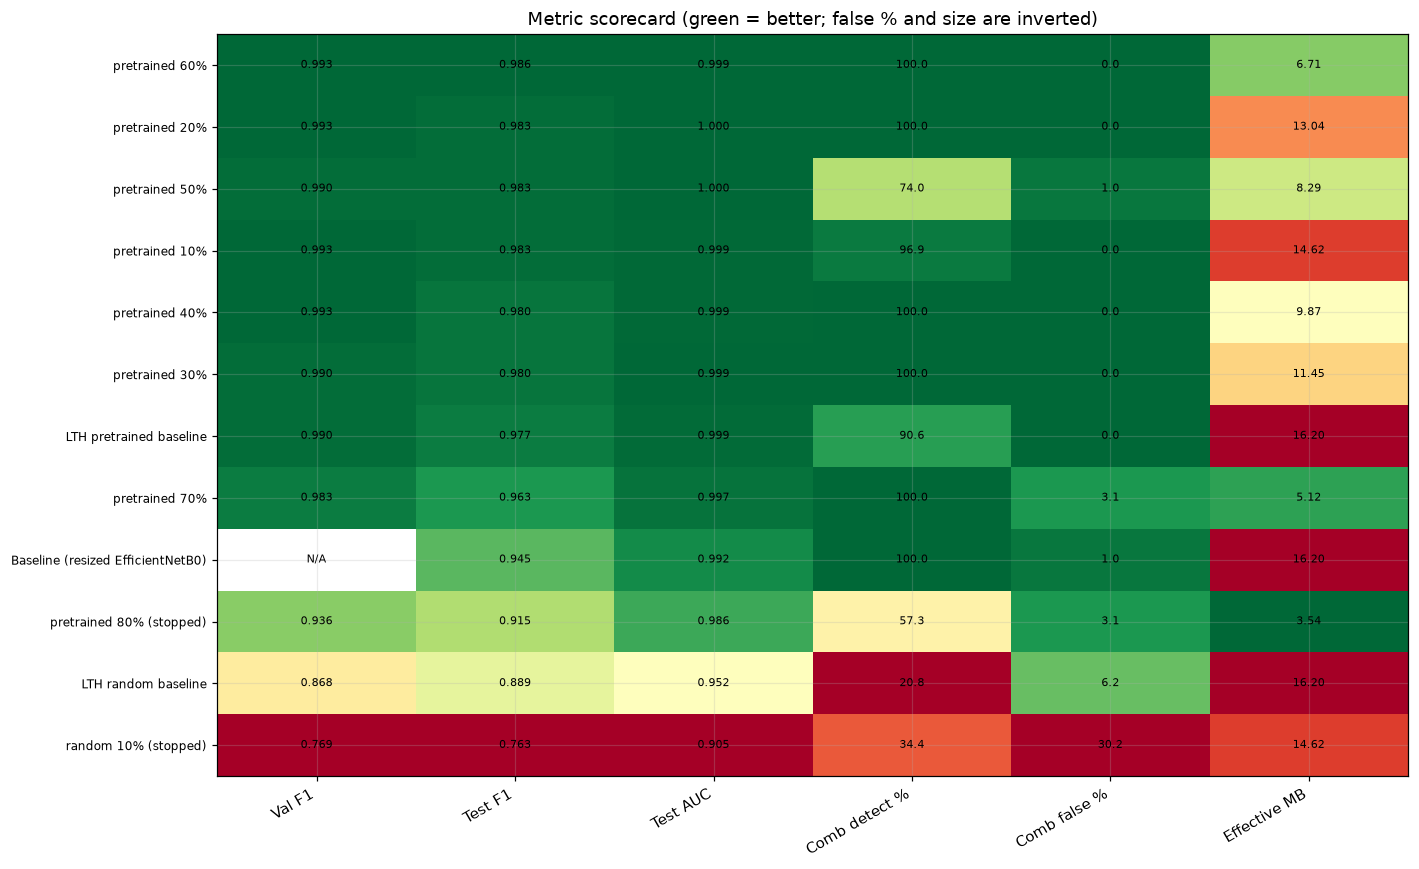

In [9]:
heat_cols = [
    ("val_f1", "Val F1"),
    ("test_f1", "Test F1"),
    ("test_auc", "Test AUC"),
    ("comb_detect_pct", "Comb detect %"),
    ("comb_false_pct", "Comb false %"),
    ("effective_mb", "Effective MB"),
]
hm = df.sort_values("test_f1", ascending=False).reset_index(drop=True)
raw = hm[[c for c, _ in heat_cols]].astype(float).to_numpy()
norm = np.full_like(raw, np.nan, dtype=float)
for j, (c, _) in enumerate(heat_cols):
    x = raw[:, j]
    lo, hi = np.nanmin(x), np.nanmax(x)
    z = (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)
    if c in ("comb_false_pct", "effective_mb"):
        z = 1.0 - z
    norm[:, j] = z

fig, ax = plt.subplots(figsize=(13, max(4.5, 0.5 * len(hm) + 2)))
ax.imshow(np.ma.masked_invalid(norm), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(heat_cols)))
ax.set_xticklabels([t for _, t in heat_cols], rotation=30, ha="right")
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(hm["label"], fontsize=8)
for i in range(len(hm)):
    for j, (c, _) in enumerate(heat_cols):
        v = raw[i, j]
        if np.isnan(v):
            txt = "N/A"
        elif c in ("val_f1", "test_f1", "test_auc"):
            txt = f"{v:.3f}"
        elif c in ("comb_detect_pct", "comb_false_pct"):
            txt = f"{v:.1f}"
        else:
            txt = f"{v:.2f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=7)
ax.set_title("Metric scorecard (green = better; false % and size are inverted)")
plt.tight_layout()
fig.savefig(OUT_ROOT / "lth_report_metrics_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

In [10]:
best_val = df[df["stage"] == "ticket"].sort_values("val_f1", ascending=False).iloc[0]
best_test = df[df["stage"] == "ticket"].sort_values("test_f1", ascending=False).iloc[0]
best_size = df[df["stage"] == "ticket"].sort_values("effective_mb").iloc[0]
stopped = df[df["status"] == "stopped"]

def val(v, digits=3):
    return "N/A" if pd.isna(v) else f"{v:.{digits}f}"

print("BASELINE MODEL TRAINED ON THE SAME RESIZED DATA")
print(f"  test F1={val(prod['test_f1'])} | AUC={val(prod['test_auc'])} | "
      f"comb detect={val(prod['comb_detect_pct'],1)}% | comb false={val(prod['comb_false_pct'],1)}%")
print(f"  effective size={val(prod['effective_mb'],2)} MB | keras={val(prod['keras_mb'],2)} MB | "
      f"TFLite dynamic={val(prod['tflite_dyn_mb'],2)} MB | latency={val(prod['latency_ms'],2)} ms")
print()
print("LTH BASELINES")
for _, r in df[df["stage"] == "baseline"].iterrows():
    print(f"  {r['label']}: val F1={val(r['val_f1'])} | test F1={val(r['test_f1'])} | "
          f"comb detect={val(r['comb_detect_pct'],1)}% | effective={val(r['effective_mb'],2)} MB")
print()
print("BEST VALIDATION TICKET")
print(f"  {best_val['label']} — val F1={val(best_val['val_f1'])}, test F1={val(best_val['test_f1'])}, "
      f"comb detect={val(best_val['comb_detect_pct'],1)}%, effective={val(best_val['effective_mb'],2)} MB "
      f"({val(best_val['effective_size_reduction_pct'],1)}% smaller)")
print("BEST TEST TICKET")
print(f"  {best_test['label']} — test F1={val(best_test['test_f1'])}, val F1={val(best_test['val_f1'])}, "
      f"comb detect={val(best_test['comb_detect_pct'],1)}%, effective={val(best_test['effective_mb'],2)} MB "
      f"({val(best_test['effective_size_reduction_pct'],1)}% smaller)")
print("SMALLEST TICKET")
print(f"  {best_size['label']} — effective={val(best_size['effective_mb'],2)} MB, "
      f"test F1={val(best_size['test_f1'])}, comb detect={val(best_size['comb_detect_pct'],1)}%")
print()
print("STOPPED ROUNDS")
for _, r in stopped.iterrows():
    base = base_val.get(r["init"], np.nan)
    print(f"  {r['label']}: val F1={val(r['val_f1'])} vs {r['init']} baseline {val(base)} "
          f"(drop {val(base - r['val_f1'])})")
print()
print("OUTPUT FIGURES")
for name in [
    "lth_report_all_models_performance.png",
    "lth_report_performance_vs_sparsity.png",
    "lth_report_size_vs_performance.png",
    "lth_report_deltas_vs_baseline.png",
    "lth_report_roc_all_models.png",
    "lth_report_metrics_heatmap.png",
]:
    p = OUT_ROOT / name
    print(f"  {p} ({p.stat().st_size if p.exists() else 'MISSING'} bytes)")

BASELINE MODEL TRAINED ON THE SAME RESIZED DATA
  test F1=0.945 | AUC=0.992 | comb detect=100.0% | comb false=1.0%
  effective size=16.20 MB | keras=17.04 MB | TFLite dynamic=N/A MB | latency=N/A ms

LTH BASELINES
  LTH pretrained baseline: val F1=0.990 | test F1=0.977 | comb detect=90.6% | effective=16.20 MB
  LTH random baseline: val F1=0.868 | test F1=0.889 | comb detect=20.8% | effective=16.20 MB

BEST VALIDATION TICKET
  pretrained 10% — val F1=0.993, test F1=0.983, comb detect=96.9%, effective=14.62 MB (9.8% smaller)
BEST TEST TICKET
  pretrained 60% — test F1=0.986, val F1=0.993, comb detect=100.0%, effective=6.71 MB (58.6% smaller)
SMALLEST TICKET
  pretrained 80% (stopped) — effective=3.54 MB, test F1=0.915, comb detect=57.3%

STOPPED ROUNDS
  pretrained 80% (stopped): val F1=0.936 vs pretrained baseline 0.990 (drop 0.054)
  random 10% (stopped): val F1=0.769 vs random baseline 0.868 (drop 0.099)

OUTPUT FIGURES
  /home/jackm/liceDetection/ParasiteID/resized/lottery_ticket/lth

## Interpretation

- The **baseline trained on the resized data** is the reference. It reaches test F1 **0.945**, AUC **0.992**, comb detection **100%**, comb false **1.04%**, at effective size **16.20 MB**.
- The **LTH pretrained baseline** has higher held-out test F1 (**0.977**), but lower comb-OOD detection (**90.6%**) than the resized baseline.
- The best ticket by validation F1 is **pretrained 10%**: test F1 **0.983**, comb detect **96.9%**, effective size **14.62 MB** (9.8% smaller).
- The best ticket by held-out test F1 is **pretrained 60%**: test F1 **0.986**, comb detect **100%**, effective size **6.71 MB** (58.6% smaller).
- The random-init run stopped at **10%** because validation F1 dropped from **0.868** to **0.769**, well beyond the 0.01 tolerance, so no further random tickets were trained.
- TFLite dynamic size is available for the baseline/two best tickets only; ticket TFLite size stays ~4.58 MB because unstructured zeros do not compress. Production TFLite and latency remain **N/A**.